# Activity 6.01 — Visualizing Stock Trends Using a Line Plot

**Student:** LU MENGJIE (MC643920)  
**Purpose:** Read the five supplied historical stock CSV files and compare closing prices over the supplied five-year period.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from pathlib import Path

def locate_datasets():
    here = Path.cwd().resolve()
    for folder in (here, *here.parents):
        candidate = folder / "Datasets"
        if candidate.is_dir():
            return candidate
    raise FileNotFoundError("Could not find the project Datasets folder.")

DATASETS = locate_datasets()
print("Datasets:", DATASETS)

Datasets: C:\Users\22392\Desktop\cisc7204_sugex06_mc643920\Submission\cisc7204_sugex06_MC643920\Datasets


In [2]:
stock_files = {
    'Google': 'GOOGL_data.csv',
    'Facebook': 'FB_data.csv',
    'Apple': 'AAPL_data.csv',
    'Amazon': 'AMZN_data.csv',
    'Microsoft': 'MSFT_data.csv',
}
series = []
for company, filename in stock_files.items():
    stock = pd.read_csv(DATASETS / filename, parse_dates=['date'])
    series.append(stock.set_index('date')['close'].rename(company))
prices = pd.concat(series, axis=1).sort_index()
print(f'{len(prices):,} trading-day rows; {prices.index.min().date()} to {prices.index.max().date()}')
prices.head(3)

1,259 trading-day rows; 2013-02-08 to 2018-02-07


,Google,Facebook,Apple,Amazon,Microsoft
date,,,,,
2013-02-08,393.0777,28.545,67.8542,261.95,27.55
2013-02-11,391.6012,28.260,68.5614,257.21,27.86
2013-02-12,390.7403,27.370,66.8428,258.70,27.88


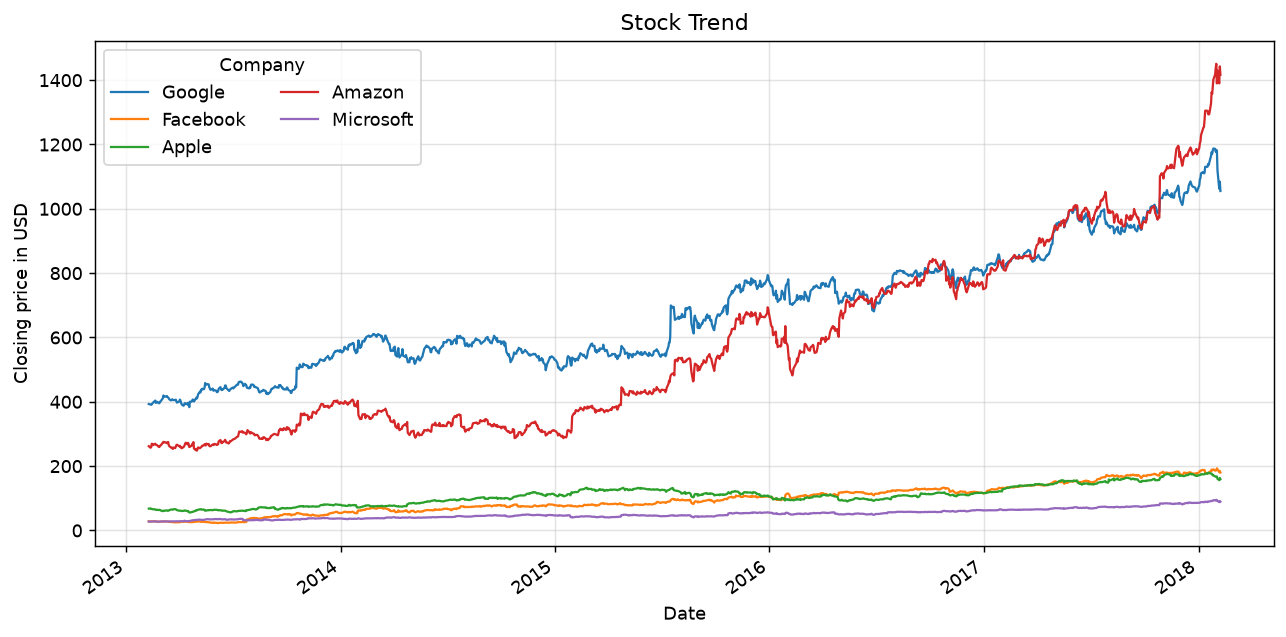

In [3]:
fig, ax = plt.subplots(figsize=(10, 5), dpi=130)
prices.plot(ax=ax, linewidth=1.25)
ax.set_title('Stock Trend')
ax.set_xlabel('Date')
ax.set_ylabel('Closing price in USD')
ax.grid(True, alpha=0.35)
ax.legend(title='Company', ncol=2)
fig.autofmt_xdate(rotation=35)
fig.tight_layout()
plt.show()